In [1]:
import numpy as np
import os
import sys
import matplotlib.pyplot as plt
import cv2

sys.path.append("..")
from tflite_inference import TFLiteInferer, TFLiteMerged

%load_ext autoreload
%autoreload 2

2025-08-04 13:30:55.992857: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-08-04 13:30:56.009954: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-08-04 13:30:56.015151: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-08-04 13:30:56.028007: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-08-04 13:30:56.965252: W tensorflow/compiler/tf2

TensorFlow version:  2.17.0


In [2]:
def draw_output(img, output):
    tmp = img.copy()
    for box in output:
        x1, y1, w, h, conf, _, x, y = box
        x2 = x1 + w
        y2 = y1 + h
        cv2.rectangle(tmp, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.circle(tmp, (int(x), int(y)), 9, (0, 255, 0), -1)
        cv2.putText(tmp, f"{conf:.2f}", (int(x1), int(y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    plt.imshow(tmp)

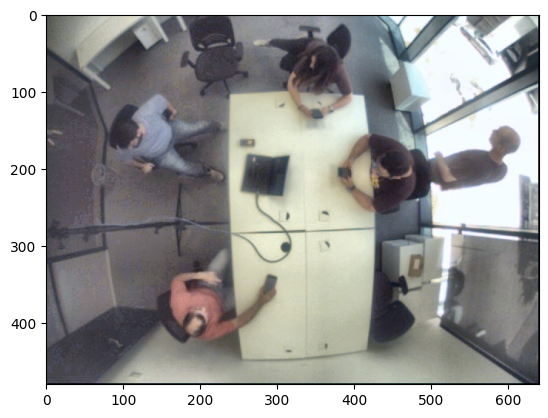

In [3]:
img_pth = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_5_margin_15_bg_wb_alif_clahe/images/val/4.2_batch2____4.2_H_cam_262_spacesMR_201.jpg"
img = cv2.imread(img_pth)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)

In [4]:
base_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_saved_model/head_float32.tflite",
    conf_th=0.20
)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [5]:
output = base_model.infer(img)
output

array([[ 79.57479858, 104.09059906, 156.44857788, 118.73403168,
          0.89444411,   0.        , 163.41456604, 168.974823  ],
       [377.2996521 , 155.93057251, 104.47747803, 103.57861328,
          0.89444411,   0.        , 426.24371338, 209.07284546],
       [304.96200562,  37.67615891,  98.28189087,  99.30024719,
          0.84678036,   0.        , 355.85296631, 101.56026459],
       [478.17895508, 140.92236328, 141.84381104,  90.32310486,
          0.84678036,   0.        , 492.78146362, 204.3894043 ],
       [157.62878418, 295.16271973, 141.60894775, 130.95065308,
          0.84678036,   0.        , 226.14569092, 355.4145813 ]])

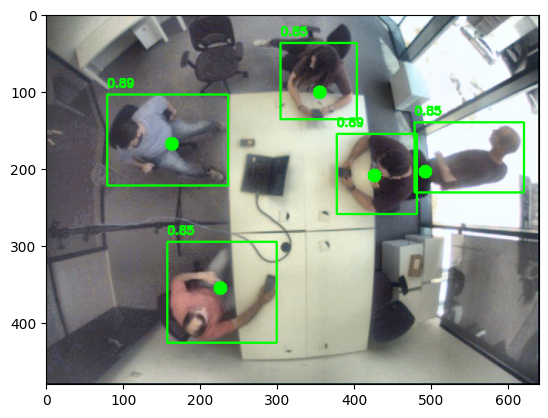

In [6]:
draw_output(img, output)

In [7]:
sep_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model/head_float32.tflite",
    conf_th=0.20,
    separated_head=True
)

In [8]:
output = sep_model.infer(img)
output

array([[ 79.57479858, 104.09059906, 156.44857788, 118.73403168,
          0.89444411,   0.        , 163.41456604, 168.974823  ],
       [377.2996521 , 155.93057251, 104.47747803, 103.57861328,
          0.89444411,   0.        , 426.24371338, 209.07284546],
       [304.96200562,  37.67615891,  98.28189087,  99.30024719,
          0.84678036,   0.        , 355.85296631, 101.56026459],
       [478.17895508, 140.92236328, 141.84381104,  90.32310486,
          0.84678036,   0.        , 492.78146362, 204.3894043 ],
       [157.62878418, 295.16271973, 141.60894775, 130.95065308,
          0.84678036,   0.        , 226.14569092, 355.4145813 ]])

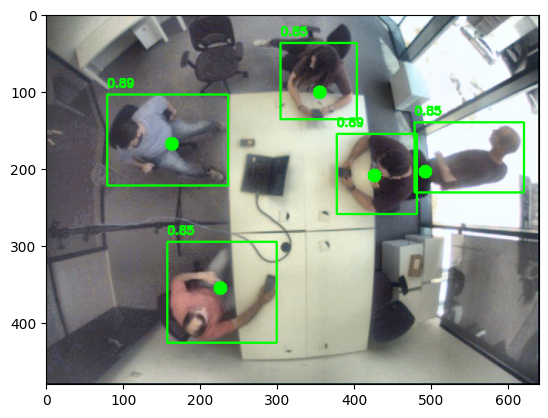

In [9]:
draw_output(img, output)

In [10]:
sep_quant_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model_100/head_full_integer_quant.tflite",
    conf_th=0.35,
    separated_head=True,
    head_int8=True,
    iou_th=0.35,
    # idxs=[1, 6, 4, 3, 2, 5, 0]  # Adjust the indices based on your model's output structure
)

In [11]:
output = sep_quant_model.infer(img)
output

array([[122.21761322, 122.21761322, 122.21761322, 122.21761322,
          0.890625  ,   0.        , 160.41061401, 160.41061401],
       [366.65283203, 122.21761322, 122.21761322, 122.21761322,
          0.890625  ,   0.        , 412.48443604, 206.24221802],
       [366.65283203,   0.        ,   0.        , 122.21761322,
          0.84375   ,   0.        , 366.65283203,  84.02461243],
       [244.43522644,   0.        , 122.21761322, 122.21761322,
          0.84375   ,   0.        , 366.65283203,  84.02461243],
       [488.87045288, 122.21761322, 122.21761322, 122.21761322,
          0.84375   ,   0.        , 488.87045288, 206.24221802],
       [122.21761322, 244.43522644, 122.21761322, 122.21761322,
          0.84375   ,   0.        , 244.43522644, 366.65283203],
       [305.54403687,  61.10880661, 122.21761322,  61.10880661,
          0.78125   ,   0.        , 374.29144287, 106.94041443]])

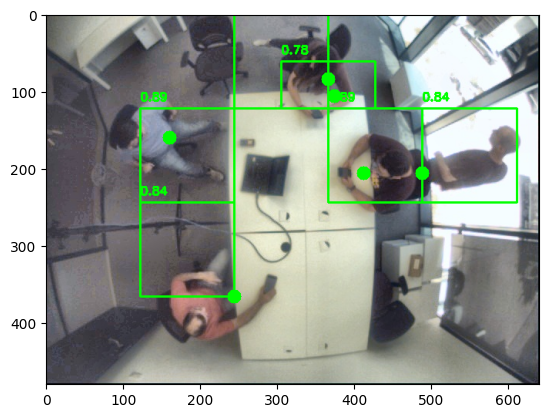

In [12]:
draw_output(img, output)

In [13]:
sep_quant_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model_200/head_full_integer_quant.tflite",
    conf_th=0.35,
    separated_head=True,
    head_int8=True,
    iou_th=0.35,
    # idxs=[1, 6, 4, 3, 2, 5, 0]  # Adjust the indices based on your model's output structure
)

In [14]:
output = sep_quant_model.infer(img)
output

array([[122.1713562 , 122.1713562 , 122.1713562 , 122.1713562 ,
          0.85546875,   0.        , 167.98561096, 167.98561096],
       [366.5140686 , 122.1713562 , 122.1713562 , 122.1713562 ,
          0.85546875,   0.        , 412.32833862, 206.16416931],
       [305.42840576,  61.0856781 , 122.1713562 ,  61.0856781 ,
          0.79296875,   0.        , 374.14978027, 106.89993286],
       [366.5140686 ,   0.        ,   0.        , 122.1713562 ,
          0.79296875,   0.        , 366.5140686 ,  83.99280548],
       [244.3427124 ,   0.        , 122.1713562 , 122.1713562 ,
          0.79296875,   0.        , 366.5140686 , 122.1713562 ],
       [488.6854248 , 122.1713562 , 122.1713562 , 122.1713562 ,
          0.79296875,   0.        , 496.32113647, 206.16416931],
       [122.1713562 , 244.3427124 , 122.1713562 , 122.1713562 ,
          0.79296875,   0.        , 244.3427124 , 366.5140686 ]])

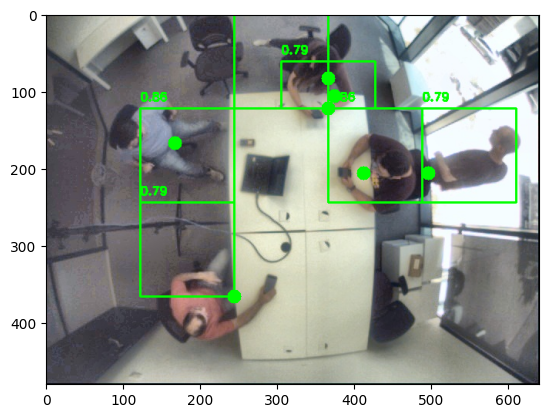

In [15]:
draw_output(img, output)

In [16]:
sep_quant_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model_300/head_full_integer_quant.tflite",
    conf_th=0.35,
    separated_head=True,
    head_int8=True,
    iou_th=0.35,
    # idxs=[1, 6, 4, 3, 2, 5, 0]  # Adjust the indices based on your model's output structure
)

In [17]:
output = sep_quant_model.infer(img)
output

array([[122.17494965, 122.17494965, 122.17494965, 122.17494965,
          0.85546875,   0.        , 167.99055481, 167.99055481],
       [366.52484131, 122.17494965, 122.17494965, 122.17494965,
          0.85546875,   0.        , 412.3404541 , 206.17022705],
       [305.43737793,  61.08747482, 122.17494965,  61.08747482,
          0.7890625 ,   0.        , 374.16079712, 106.9030838 ],
       [366.52484131,   0.        ,   0.        , 122.17494965,
          0.7890625 ,   0.        , 366.52484131,  83.9952774 ],
       [244.34989929,   0.        , 122.17494965, 122.17494965,
          0.7890625 ,   0.        , 366.52484131,  83.9952774 ],
       [488.69979858, 122.17494965, 122.17494965, 122.17494965,
          0.7890625 ,   0.        , 496.33572388, 206.17022705],
       [122.17494965, 244.34989929, 122.17494965, 122.17494965,
          0.7890625 ,   0.        , 206.17022705, 366.52484131]])

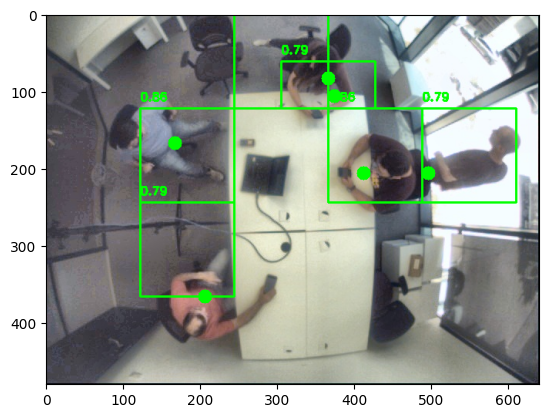

In [18]:
draw_output(img, output)

In [19]:
sep_quant_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model_400/head_full_integer_quant.tflite",
    conf_th=0.35,
    separated_head=True,
    head_int8=True,
    iou_th=0.35,
    # idxs=[1, 6, 4, 3, 2, 5, 0]  # Adjust the indices based on your model's output structure
)

In [20]:
output = sep_quant_model.infer(img)
output

array([[122.16242218, 122.16242218, 122.16242218, 122.16242218,
          0.85546875,   0.        , 167.97332764, 167.97332764],
       [366.48727417, 122.16242218, 122.16242218, 122.16242218,
          0.85546875,   0.        , 412.29818726, 206.14909363],
       [305.40606689,  61.08121109, 122.16242218,  61.08121109,
          0.7890625 ,   0.        , 374.12240601, 106.89212036],
       [366.48727417,   0.        ,   0.        , 122.16242218,
          0.7890625 ,   0.        , 366.48727417,  83.98666382],
       [244.32484436,   0.        , 122.16242218, 122.16242218,
          0.7890625 ,   0.        , 366.48727417,  83.98666382],
       [488.64968872, 122.16242218, 122.16242218, 122.16242218,
          0.7890625 ,   0.        , 496.28485107, 206.14909363],
       [122.16242218, 244.32484436, 122.16242218, 122.16242218,
          0.7890625 ,   0.        , 206.14909363, 366.48727417]])

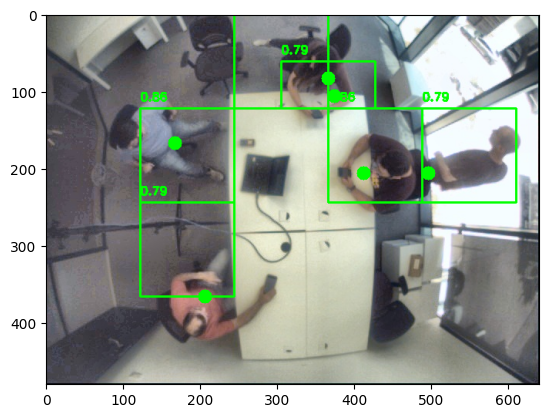

In [21]:
draw_output(img, output)

In [22]:
import onnxruntime as ort
import numpy as np

In [23]:
# Load the merged model
session = ort.InferenceSession("combined.onnx", providers=["CPUExecutionProvider"])

In [24]:
input_name = session.get_inputs()[0].name
input_name

'images'

In [25]:
input_data = sep_quant_model.pre_process(img)
input_data.shape
input_data = np.transpose(input_data, (0, 3, 1, 2)).astype(np.float32) / 255  # Ensure the input is in float32 format

In [26]:
bboxes, scores = session.run(None, {input_name: input_data})

In [27]:
outputs = np.concatenate([bboxes[:, :, :4], scores, bboxes[:, :, 4:]], axis=-1)
outputs.shape

(1, 2100, 7)

In [28]:
detections = sep_quant_model.post_process(outputs)
detections.shape

(5, 8)

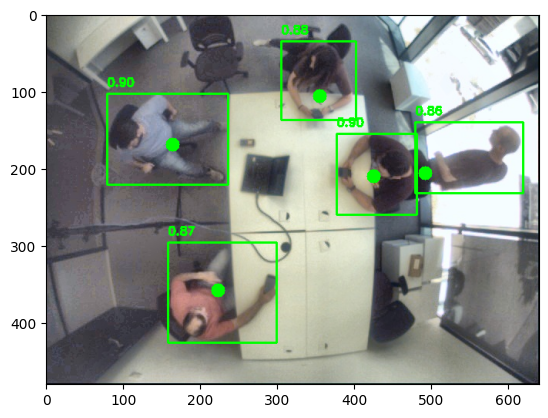

In [29]:
draw_output(img, detections)

In [30]:
combined_quant_model = TFLiteInferer(
    yolo_pth="combined/combined_full_integer_quant.tflite",
    conf_th=0.25,
    iou_th=0.35
)

In [31]:
scores, bboxes = combined_quant_model.infer_no_head(img, quantized_output=False)
scores.shape, bboxes.shape

((1, 2100, 1), (1, 2100, 6))

In [32]:
raw_outputs = np.concatenate([bboxes[:, :, :4], scores, bboxes[:, :, 4:]], axis=-1)
outputs = combined_quant_model.post_process(raw_outputs)
outputs

array([[367.69711304, 183.84855652, 122.56570435,  61.28285217,
          0.91015625,   0.        , 409.82907104, 206.82962036],
       [306.41424561,  61.28285217, 122.56570435,  61.28285217,
          0.86328125,   0.        , 371.52728271, 122.56570435],
       [ 61.28285217, 122.56570435, 183.84855652, 122.56570435,
          0.86328125,   0.        , 164.69766235, 164.69766235],
       [486.43264771, 122.56570435, 122.56570435, 122.56570435,
          0.86328125,   0.        , 494.09298706, 206.82962036],
       [183.84855652, 306.41424561, 122.56570435, 122.56570435,
          0.86328125,   0.        , 206.82962036, 371.52728271]])

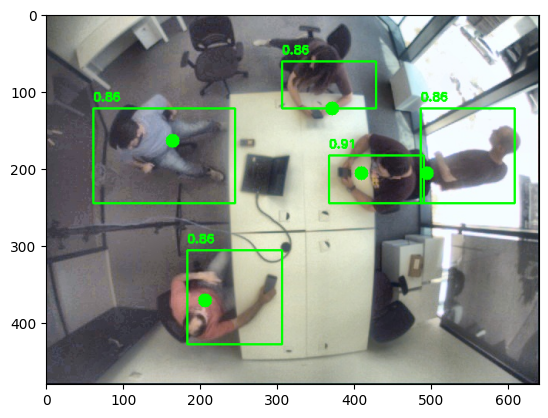

In [33]:
draw_output(img, outputs)

In [34]:
outputs = combined_quant_model.infer_bottleneck(img)
outputs

array([[367.69711304, 183.84855652, 122.56570435,  61.28285217,
          0.91015625,   0.        , 409.82907104, 206.82962036],
       [306.41424561,  61.28285217, 122.56570435,  61.28285217,
          0.86328125,   0.        , 371.52728271, 122.56570435],
       [ 61.28285217, 122.56570435, 183.84855652, 122.56570435,
          0.86328125,   0.        , 164.69766235, 164.69766235],
       [486.43264771, 122.56570435, 122.56570435, 122.56570435,
          0.86328125,   0.        , 494.09298706, 206.82962036],
       [183.84855652, 306.41424561, 122.56570435, 122.56570435,
          0.86328125,   0.        , 206.82962036, 371.52728271]])

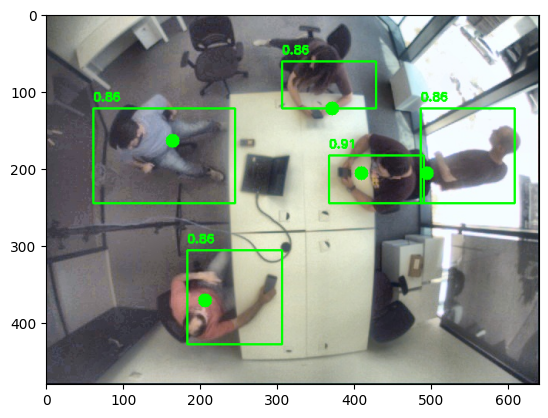

In [35]:
draw_output(img, outputs)

In [36]:
combined_quant_model = TFLiteInferer(
    yolo_pth="combined_per_channel/combined_full_integer_quant.tflite",
    conf_th=0.25,
    iou_th=0.4
)

In [37]:
outputs = combined_quant_model.infer_bottleneck(img)
outputs

array([[ 61.28285217, 122.56570435, 183.84855652, 122.56570435,
          0.91015625,   0.        , 164.69766235, 164.69766235],
       [367.69711304, 183.84855652, 122.56570435,  61.28285217,
          0.91015625,   0.        , 409.82907104, 206.82962036],
       [306.41424561,  30.64142609,  91.92427826, 122.56570435,
          0.86328125,   0.        , 371.52728271, 103.41481018],
       [486.43264771, 122.56570435, 122.56570435, 122.56570435,
          0.86328125,   0.        , 494.09298706, 206.82962036],
       [183.84855652, 306.41424561, 122.56570435, 122.56570435,
          0.86328125,   0.        , 245.13140869, 371.52728271]])

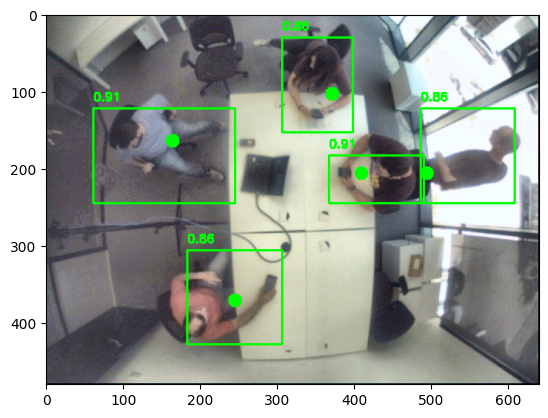

In [38]:
draw_output(img, outputs)

In [39]:
full_quant_model = TFLiteInferer(
    yolo_pth="best_full_saved_model/best_full_full_integer_quant.tflite",
    conf_th=0.25,
)

In [40]:
raw_output = full_quant_model.infer_no_head(img)[0]
raw_output.shape, raw_output[:, 4, :].max()

((1, 7, 2100), 0.86748874)

In [41]:
outputs = full_quant_model.post_process(raw_output)
outputs

array([], dtype=float64)

In [49]:
combined_quant_model = TFLiteMerged(
    yolo_pth="combined_per_channel/combined_full_integer_quant.tflite",
    conf_th=0.25,
    iou_th=0.35
)

In [50]:
outputs = combined_quant_model.infer(img)
outputs

array([[ 61.28285217, 122.56570435, 183.84855652, 122.56570435,
          0.91015625,   0.        , 164.69766235, 164.69766235],
       [367.69711304, 183.84855652, 122.56570435,  61.28285217,
          0.91015625,   0.        , 409.82907104, 206.82962036],
       [306.41424561,  30.64142609,  91.92427826, 122.56570435,
          0.86328125,   0.        , 371.52728271, 103.41481018],
       [486.43264771, 122.56570435, 122.56570435, 122.56570435,
          0.86328125,   0.        , 494.09298706, 206.82962036],
       [183.84855652, 306.41424561, 122.56570435, 122.56570435,
          0.86328125,   0.        , 245.13140869, 371.52728271]])

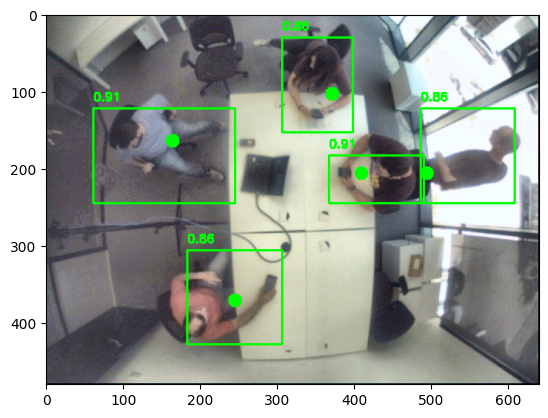

In [51]:
draw_output(img, outputs)

In [52]:
combined_quant_model = TFLiteMerged(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    conf_th=0.25,
    iou_th=0.35
)

In [53]:
outputs = combined_quant_model.infer(img)
outputs

array([[ 61.28285217, 122.56570435, 183.84855652, 122.56570435,
          0.91015625,   0.        , 164.69766235, 164.69766235],
       [367.69711304, 183.84855652, 122.56570435,  61.28285217,
          0.91015625,   0.        , 409.82907104, 206.82962036],
       [306.41424561,  30.64142609,  91.92427826, 122.56570435,
          0.86328125,   0.        , 371.52728271, 103.41481018],
       [486.43264771, 122.56570435, 122.56570435, 122.56570435,
          0.86328125,   0.        , 494.09298706, 206.82962036],
       [183.84855652, 306.41424561, 122.56570435, 122.56570435,
          0.86328125,   0.        , 245.13140869, 371.52728271]])

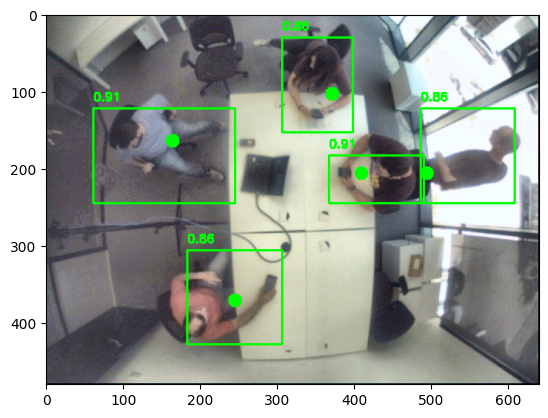

In [54]:
draw_output(img, outputs)